## 1. Install (Colab)

In [1]:
!pip install -q yfinance

## 2. Imports

In [2]:
import os, json, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())


torch 2.10.0+cu128 | cuda available: True


## 3. Config



In [3]:
UNIVERSE = [
    "AAPL","MSFT","NVDA","AMZN","META","GOOGL","GOOG","TSLA","AVGO","ORCL",
    "CRM","ADBE","AMD","INTC","QCOM","CSCO","TXN","IBM","NOW","INTU",
    "JPM","BAC","WFC","C","GS","MS","BLK","SCHW","AXP","USB",
    "UNH","JNJ","LLY","PFE","ABBV","TMO","MRK","ABT","DHR","BMY",
    "WMT","COST","HD","LOW","TGT","MCD","SBUX","NKE","KO","PEP",
    "CAT","DE","BA","HON","UPS","XOM","CVX","COP","LIN","APD",
    "DIS","NFLX","CMCSA","T","VZ",
]

START_DATE = "2010-01-01"
END_DATE   = "2025-12-31"
TRAIN_END  = "2020-12-31"
VALID_END  = "2022-12-31"

FORWARD_DAYS = 5
HOLD_DAYS    = 5
TOP_Q        = 0.20
BOTTOM_Q     = 0.20

SEQ_LEN      = 30         # lookback window in trading days
HIDDEN       = 64
NUM_LAYERS   = 2
DROPOUT      = 0.30
HEAD_HIDDEN  = 32

SEEDS        = [11, 22, 33, 44, 55]
MAX_EPOCHS   = 25
BATCH_SIZE   = 512
LR           = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE     = 5

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUTPUT_DIR = "lstm_alpha_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)


## 4. Download prices (yfinance, adjusted)

In [4]:
def download_prices(tickers, start, end):
    print(f"Downloading {len(tickers)} tickers from {start} to {end} ...")
    df = yf.download(
        tickers=tickers, start=start, end=end,
        auto_adjust=True, progress=False,
        group_by="ticker", threads=True,
    )
    frames = []
    for t in tickers:
        if t not in df.columns.get_level_values(0):
            continue
        sub = df[t].copy()
        if sub.dropna(how="all").empty:
            continue
        sub.columns = [c.lower() for c in sub.columns]
        sub["ticker"] = t
        sub = sub.reset_index().rename(columns={"Date": "date"})
        frames.append(sub[["date","ticker","open","high","low","close","volume"]])
    out = pd.concat(frames, ignore_index=True)
    out["date"] = pd.to_datetime(out["date"])
    out = out.dropna(subset=["close"]).sort_values(["ticker","date"]).reset_index(drop=True)
    return out

prices = download_prices(UNIVERSE, START_DATE, END_DATE)
print(f"Got {prices['ticker'].nunique()} tickers, {len(prices):,} rows")
prices.head()


Got 65 tickers, 259,392 rows


,date,ticker,open,high,low,close,volume
0,2010-01-04,AAPL,6.395005,6.427066,6.363544,6.412384,493729600.0
1,2010-01-05,AAPL,6.430062,6.459725,6.389611,6.423470,601904800.0
2,2010-01-06,AAPL,6.423470,6.448938,6.314704,6.321296,552160000.0
3,2010-01-07,AAPL,6.344667,6.352158,6.263767,6.309610,477131200.0
4,2010-01-08,AAPL,6.301220,6.352158,6.264067,6.351558,447610800.0


## 5. Features (per-day, primitive — LSTM builds its own)

We intentionally give fewer, lower-level features than the MLP. The LSTM's job is to turn these into temporal representations. Eight per-day signals:

- `ret_1d`, `ret_5d` — short-term returns
- `vol_21d` — realized volatility regime
- `rsi_14` — oscillator
- `hl_spread`, `oc_spread` — intraday range and direction
- `vol_ratio_21` — volume anomaly vs recent average
- `p_to_ma21` — trend vs 21-day MA

In [5]:
def compute_rsi(series, window=14):
    delta = series.diff()
    gain = delta.clip(lower=0); loss = -delta.clip(upper=0)
    ag = gain.rolling(window).mean(); al = loss.rolling(window).mean()
    rs = ag / (al + 1e-12)
    return 100 - 100/(1+rs)

def make_features(data, forward_days=5):
    df = data.copy()
    g = df.groupby("ticker")

    df["ret_1d"] = g["close"].pct_change(1)
    df["ret_5d"] = g["close"].pct_change(5)

    df["vol_21d"] = g["ret_1d"].transform(lambda x: x.rolling(21).std())
    df["rsi_14"]  = g["close"].transform(lambda x: compute_rsi(x, 14))

    df["hl_spread"] = (df["high"] - df["low"])  / (df["close"] + 1e-12)
    df["oc_spread"] = (df["close"] - df["open"]) / (df["open"]  + 1e-12)

    vma21 = g["volume"].transform(lambda x: x.rolling(21).mean())
    df["vol_ratio_21"] = df["volume"] / (vma21 + 1e-8)

    ma21 = g["close"].transform(lambda x: x.rolling(21).mean())
    df["p_to_ma21"] = df["close"] / ma21 - 1

    # forward return (target base)
    df["fwd_ret"] = g["close"].shift(-forward_days) / df["close"] - 1
    return df

feat = make_features(prices, forward_days=FORWARD_DAYS)
feat.tail()


,date,ticker,open,high,low,close,volume,ret_1d,ret_5d,vol_21d,rsi_14,hl_spread,oc_spread,vol_ratio_21,p_to_ma21,fwd_ret
259387,2025-12-23,XOM,117.685581,119.235249,117.536573,118.629288,12567600.0,0.010749,0.041332,0.012654,54.844484,0.014319,0.008019,0.764131,0.020501,NaN
259388,2025-12-24,XOM,118.539891,119.255124,118.331282,118.430618,6137400.0,-0.001675,0.015416,0.012443,56.396080,0.007801,-0.000922,0.386477,0.017446,NaN
259389,2025-12-26,XOM,118.102798,118.758432,117.745181,118.321342,8066100.0,-0.000923,0.022052,0.012042,58.148373,0.008564,0.001850,0.517818,0.014611,NaN
259390,2025-12-29,XOM,119.354460,120.496847,118.609426,119.731941,14782500.0,0.011922,0.032908,0.012237,63.680082,0.015764,0.003163,0.939989,0.024314,NaN
259391,2025-12-30,XOM,120.298168,120.993538,119.831279,120.188896,11150500.0,0.003816,0.024037,0.012119,59.244257,0.009670,-0.000908,0.700742,0.026117,NaN


## 6. Cross-sectional standardization



In [6]:
FEATURE_COLS = [
    "ret_1d","ret_5d","vol_21d","rsi_14",
    "hl_spread","oc_spread","vol_ratio_21","p_to_ma21",
]
N_FEATURES = len(FEATURE_COLS)

def _cs_rank_center(s): return s.rank(pct=True) - 0.5
def _cs_zscore(s):
    mu, sd = s.mean(), s.std()
    if sd is None or sd == 0 or np.isnan(sd): return s*0.0
    return (s - mu) / sd

def cross_sectional_prepare(df):
    work = df[["date","ticker"] + FEATURE_COLS + ["fwd_ret"]].copy()
    work = work.replace([np.inf,-np.inf], np.nan)
    # need features filled for full sequence, target only needed at prediction date
    for col in FEATURE_COLS:
        z = work.groupby("date")[col].transform(_cs_zscore)
        work[col] = z.clip(-5, 5)
    work["target"] = work.groupby("date")["fwd_ret"].transform(_cs_rank_center)
    return work

ds = cross_sectional_prepare(feat)
print("After CS prep, non-null fwd_ret rows:", ds["fwd_ret"].notna().sum())
ds.head()


After CS prep, non-null fwd_ret rows: 259067


,date,ticker,ret_1d,ret_5d,vol_21d,rsi_14,hl_spread,oc_spread,vol_ratio_21,p_to_ma21,fwd_ret,target
0,2010-01-04,AAPL,NaN,NaN,NaN,NaN,-1.073184,-0.189548,NaN,NaN,-0.018223,-0.286885
1,2010-01-05,AAPL,-0.049810,NaN,NaN,NaN,-0.923063,-0.288379,NaN,NaN,-0.031066,-0.254098
2,2010-01-06,AAPL,-1.150715,NaN,NaN,NaN,0.250938,-1.299433,NaN,NaN,-0.001517,-0.090164
3,2010-01-07,AAPL,-0.325481,NaN,NaN,NaN,-0.695465,-0.585294,NaN,NaN,-0.005461,-0.057377
4,2010-01-08,AAPL,0.290941,NaN,NaN,NaN,-0.639908,0.220931,NaN,NaN,-0.028540,-0.221311


## 7. Build sequences (the key LSTM step)



In [7]:
def build_sequences(df, feature_cols, seq_len):
    """
    Sliding-window sequences per ticker.

    For each ticker, sort by date, fill CS-standardized features forward for
    isolated NaNs (rare, but robust), drop any remaining NaN rows, and emit
    the last `seq_len` rows ending at row i as the input for target y[i].
    """
    X_list, y_list, d_list, t_list = [], [], [], []
    for ticker, g in df.groupby("ticker"):
        g = g.sort_values("date").reset_index(drop=True)
        # forward-fill small gaps (e.g., feature NaN on a stock's IPO date)
        feats = g[feature_cols].ffill().bfill()
        # drop rows where features still NaN (very start of history)
        valid_feat = feats.notna().all(axis=1)
        # only predict on rows with a target
        has_tgt = g["target"].notna()

        feats_arr = feats.values.astype(np.float32)
        target_arr = g["target"].values.astype(np.float32)
        dates_arr = g["date"].values
        valid_mask = valid_feat.values & has_tgt.values

        for i in range(seq_len - 1, len(g)):
            if not valid_mask[i]:
                continue
            window = feats_arr[i - seq_len + 1 : i + 1]
            if np.isnan(window).any():
                continue
            X_list.append(window)
            y_list.append(target_arr[i])
            d_list.append(dates_arr[i])
            t_list.append(ticker)

    X = np.stack(X_list, axis=0)
    y = np.array(y_list, dtype=np.float32)
    d = np.array(d_list)
    t = np.array(t_list)
    return X, y, d, t

print("Building sequences (this takes ~30-60 seconds)...")
X_all, y_all, dates_all, tickers_all = build_sequences(ds, FEATURE_COLS, SEQ_LEN)
print("X_all:", X_all.shape, "| y_all:", y_all.shape)
print("Size in MB:", X_all.nbytes / 1e6)


Building sequences (this takes ~30-60 seconds)...
X_all: (257182, 30, 8) | y_all: (257182,)
Size in MB: 246.89472


## 8. Train / valid / test split by date

In [8]:
train_end = pd.Timestamp(TRAIN_END)
valid_end = pd.Timestamp(VALID_END)

is_train = dates_all <= np.datetime64(train_end)
is_valid = (dates_all > np.datetime64(train_end)) & (dates_all <= np.datetime64(valid_end))
is_test  = dates_all > np.datetime64(valid_end)

Xtr, ytr, dtr, ttr = X_all[is_train], y_all[is_train], dates_all[is_train], tickers_all[is_train]
Xva, yva, dva, tva = X_all[is_valid], y_all[is_valid], dates_all[is_valid], tickers_all[is_valid]
Xte, yte, dte, tte = X_all[is_test],  y_all[is_test],  dates_all[is_test],  tickers_all[is_test]

print(f"Train: {len(Xtr):>8,} seqs  {pd.Timestamp(dtr.min()).date()} -> {pd.Timestamp(dtr.max()).date()}")
print(f"Valid: {len(Xva):>8,} seqs  {pd.Timestamp(dva.min()).date()} -> {pd.Timestamp(dva.max()).date()}")
print(f"Test : {len(Xte):>8,} seqs  {pd.Timestamp(dte.min()).date()} -> {pd.Timestamp(dte.max()).date()}")


Train:  175,997 seqs  2010-02-16 -> 2020-12-31
Valid:   32,695 seqs  2021-01-04 -> 2022-12-30
Test :   48,490 seqs  2023-01-03 -> 2025-12-22


## 9. LSTM model



In [9]:
class LSTMAlpha(nn.Module):
    def __init__(self, n_features, hidden=64, num_layers=2,
                 dropout=0.3, head_hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Linear(hidden, head_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, 1),
        )

    def forward(self, x):          # x: (B, T, F)
        out, _ = self.lstm(x)      # out: (B, T, H)
        last = out[:, -1, :]       # last timestep hidden state
        return self.head(last).squeeze(-1)


def _daily_rank_ic(y_true, y_pred, dates):
    d = pd.DataFrame({"y": y_true, "p": y_pred, "d": pd.Series(dates)})
    ics = []
    for _, g in d.groupby("d"):
        if len(g) < 5: continue
        r, _ = spearmanr(g["y"], g["p"])
        if not np.isnan(r): ics.append(r)
    return float(np.mean(ics)) if ics else float("nan")


def train_one_lstm(seed, Xtr, ytr, Xva, yva, dva):
    set_seed(seed)
    model = LSTMAlpha(N_FEATURES, HIDDEN, NUM_LAYERS, DROPOUT, HEAD_HIDDEN).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
    loss_fn = nn.MSELoss()

    ds_tr = TensorDataset(torch.tensor(Xtr), torch.tensor(ytr))
    dl = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)

    Xva_t = torch.tensor(Xva).to(DEVICE)

    best_ic, best_state, patience = -1e9, None, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        for xb, yb in dl:
            xb = xb.to(DEVICE); yb = yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        sched.step()

        model.eval()
        with torch.no_grad():
            pv_chunks = []
            for i in range(0, len(Xva_t), 4096):
                pv_chunks.append(model(Xva_t[i:i+4096]).cpu().numpy())
            pv = np.concatenate(pv_chunks)
        ic = _daily_rank_ic(yva, pv, dva)

        if ic > best_ic + 1e-5:
            best_ic = ic
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1

        print(f"  seed={seed} epoch={epoch+1:02d}  val_IC={ic:+.4f}  best={best_ic:+.4f}")
        if patience >= PATIENCE:
            print(f"  early-stop at epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    return model, best_ic


def predict_lstm(model, X, batch_size=4096):
    model.eval()
    X_t = torch.tensor(X)
    outs = []
    with torch.no_grad():
        for i in range(0, len(X_t), batch_size):
            chunk = X_t[i:i+batch_size].to(DEVICE)
            outs.append(model(chunk).cpu().numpy())
    return np.concatenate(outs)


## 10. Train 5-seed ensemble



In [10]:
preds_va = np.zeros(len(Xva), dtype=np.float64)
preds_te = np.zeros(len(Xte), dtype=np.float64)
seed_ics = []

for seed in SEEDS:
    print(f"\n=== Training LSTM  seed={seed}  device={DEVICE} ===")
    model, val_ic = train_one_lstm(seed, Xtr, ytr, Xva, yva, dva)
    preds_va += predict_lstm(model, Xva) / len(SEEDS)
    preds_te += predict_lstm(model, Xte) / len(SEEDS)
    seed_ics.append(val_ic)
    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, f"lstm_seed{seed}.pt"))

print("\nPer-seed val IC:", [f"{x:+.4f}" for x in seed_ics])
print(f"Mean per-seed val IC: {np.mean(seed_ics):+.4f}")



=== Training LSTM  seed=11  device=cuda ===
  seed=11 epoch=01  val_IC=-0.0162  best=-0.0162
  seed=11 epoch=02  val_IC=-0.0193  best=-0.0162
  seed=11 epoch=03  val_IC=-0.0202  best=-0.0162
  seed=11 epoch=04  val_IC=-0.0192  best=-0.0162
  seed=11 epoch=05  val_IC=-0.0180  best=-0.0162
  seed=11 epoch=06  val_IC=-0.0141  best=-0.0141
  seed=11 epoch=07  val_IC=+0.0006  best=+0.0006
  seed=11 epoch=08  val_IC=-0.0080  best=+0.0006
  seed=11 epoch=09  val_IC=-0.0058  best=+0.0006
  seed=11 epoch=10  val_IC=-0.0058  best=+0.0006
  seed=11 epoch=11  val_IC=+0.0194  best=+0.0194
  seed=11 epoch=12  val_IC=+0.0162  best=+0.0194
  seed=11 epoch=13  val_IC=+0.0243  best=+0.0243
  seed=11 epoch=14  val_IC=+0.0240  best=+0.0243
  seed=11 epoch=15  val_IC=+0.0164  best=+0.0243
  seed=11 epoch=16  val_IC=+0.0205  best=+0.0243
  seed=11 epoch=17  val_IC=+0.0213  best=+0.0243
  seed=11 epoch=18  val_IC=+0.0184  best=+0.0243
  early-stop at epoch 18

=== Training LSTM  seed=22  device=cuda ===
  s

## 11. Wrap predictions into a DataFrame for evaluation

In [11]:
valid_df = pd.DataFrame({
    "date": dva, "ticker": tva, "pred": preds_va, "target": yva,
})
test_df = pd.DataFrame({
    "date": dte, "ticker": tte, "pred": preds_te, "target": yte,
})

# attach realized fwd_ret from `ds` for L/S backtest
fwd = ds[["date","ticker","fwd_ret"]]
valid_df = valid_df.merge(fwd, on=["date","ticker"], how="left")
test_df  = test_df .merge(fwd, on=["date","ticker"], how="left")

print("valid_df:", valid_df.shape, "| test_df:", test_df.shape)
test_df.head()


valid_df: (32695, 5) | test_df: (48490, 5)


,date,ticker,pred,target,fwd_ret
0,2023-01-03,AAPL,0.023679,0.176923,0.045254
1,2023-01-04,AAPL,0.023727,0.361538,0.056426
2,2023-01-05,AAPL,0.022488,0.269231,0.067109
3,2023-01-06,AAPL,0.018029,0.146154,0.039654
4,2023-01-09,AAPL,0.014122,0.284615,0.044487


## 12. Evaluation — IC, IR, quintiles, long/short

In [12]:
def daily_ic(df, pred_col="pred", tgt_col="fwd_ret"):
    rows = []
    for d,g in df.groupby("date"):
        g = g[[pred_col, tgt_col]].dropna()
        if len(g) < 5: continue
        ic, _ = spearmanr(g[pred_col], g[tgt_col])
        rows.append((d, ic))
    return pd.DataFrame(rows, columns=["date","ic"])

def quintile_returns(df, pred_col="pred", tgt_col="fwd_ret", n_bins=5):
    rows = []
    for d,g in df.groupby("date"):
        g = g.dropna(subset=[pred_col, tgt_col]).copy()
        if len(g) < n_bins*2: continue
        g["bin"] = pd.qcut(g[pred_col].rank(method="first"), n_bins, labels=False)
        means = g.groupby("bin")[tgt_col].mean()
        rows.append([d] + list(means.values))
    cols = ["date"] + [f"q{i+1}" for i in range(n_bins)]
    out = pd.DataFrame(rows, columns=cols)
    out["ls_q5_q1"] = out[f"q{n_bins}"] - out["q1"]
    return out

def long_short_portfolio(df, top_q=0.2, bot_q=0.2):
    rows = []
    for d,g in df.groupby("date"):
        g = g.dropna(subset=["pred","fwd_ret"]).copy()
        if len(g) < 10: continue
        L = g["pred"].quantile(1 - top_q); S = g["pred"].quantile(bot_q)
        longs = g[g["pred"] >= L]; shorts = g[g["pred"] <= S]
        if len(longs)==0 or len(shorts)==0: continue
        rows.append([d, longs["fwd_ret"].mean(), shorts["fwd_ret"].mean(),
                     longs["fwd_ret"].mean() - shorts["fwd_ret"].mean(),
                     len(longs), len(shorts)])
    return pd.DataFrame(rows, columns=["date","long_ret","short_ret","ls_ret","n_l","n_s"])

def perf_stats(rets, periods_per_year=252/HOLD_DAYS):
    r = rets.dropna()
    if len(r)==0: return {}
    eq = (1+r).cumprod()
    cagr = eq.iloc[-1]**(periods_per_year/len(r)) - 1
    sharpe = r.mean()/(r.std()+1e-12)*np.sqrt(periods_per_year)
    dd = (eq/eq.cummax() - 1).min()
    return {
        "periods": int(len(r)),
        "CAGR": float(cagr),
        "ann_vol": float(r.std()*np.sqrt(periods_per_year)),
        "Sharpe": float(sharpe),
        "MaxDD": float(dd),
        "HitRate": float((r>0).mean()),
        "FinalEq": float(eq.iloc[-1]),
    }

def _ir(x): return x["ic"].mean() / (x["ic"].std() + 1e-12)

ic_val = daily_ic(valid_df)
ic_tst = daily_ic(test_df)
q_tst  = quintile_returns(test_df)
ls_val = long_short_portfolio(valid_df)
ls_tst = long_short_portfolio(test_df)

print(f"VALID  IC={ic_val['ic'].mean():+.4f}  IR={_ir(ic_val):+.3f}  hit={(ic_val['ic']>0).mean():.2%}")
print(f"TEST   IC={ic_tst['ic'].mean():+.4f}  IR={_ir(ic_tst):+.3f}  hit={(ic_tst['ic']>0).mean():.2%}")
print("\nQuintile means (TEST):")
for c, v in q_tst[[f"q{i}" for i in range(1,6)]].mean().items():
    print(f"  {c}: {v:+.4%}")
print(f"  Q5 - Q1: {q_tst['ls_q5_q1'].mean():+.4%}")
print("\nVALID L/S:", perf_stats(ls_val['ls_ret']))
print("TEST  L/S:", perf_stats(ls_tst['ls_ret']))


VALID  IC=+0.0332  IR=+0.172  hit=58.25%
TEST   IC=+0.0225  IR=+0.132  hit=53.62%

Quintile means (TEST):
  q1: +0.4047%
  q2: +0.2939%
  q3: +0.2961%
  q4: +0.4342%
  q5: +0.6369%
  Q5 - Q1: +0.2321%

VALID L/S: {'periods': 503, 'CAGR': 0.1115585157299066, 'ann_vol': 0.15675506334413272, 'Sharpe': 0.7537749926162686, 'MaxDD': -0.562642040450499, 'HitRate': 0.562624254473161, 'FinalEq': 2.8735049266927155}
TEST  L/S: {'periods': 746, 'CAGR': 0.11256147194340094, 'ann_vol': 0.1430988836140595, 'Sharpe': 0.8175281444011836, 'MaxDD': -0.4219179795208028, 'HitRate': 0.5495978552278821, 'FinalEq': 4.849187425758829}


## 13. Honest Sharpe: non-overlapping + Newey-West

5-day forward returns overlap 4/5 days at daily frequency. Report three views: naive, HAC-adjusted, and every-5th-day non-overlap.

In [13]:
def non_overlapping_subsample(df, step=5):
    udates = sorted(df["date"].unique())
    keep = set(udates[::step])
    return df[df["date"].isin(keep)].copy()

def newey_west_sharpe(rets, q=None, periods_per_year=252):
    r = pd.Series(rets).dropna().values
    n = len(r)
    if n < 20: return float("nan")
    if q is None: q = max(1, FORWARD_DAYS - 1)
    mu = r.mean()
    gamma0 = r.var(ddof=1)
    nw_var = gamma0
    for k in range(1, q+1):
        if len(r) <= k: break
        gamma_k = np.cov(r[:-k], r[k:], ddof=1)[0,1]
        w = 1.0 - k / (q + 1)
        nw_var += 2 * w * gamma_k
    if nw_var <= 0: return float("nan")
    return float(mu / np.sqrt(nw_var) * np.sqrt(periods_per_year))

def honest_eval_block(test_df, label):
    ic = daily_ic(test_df)
    q  = quintile_returns(test_df)
    ls = long_short_portfolio(test_df, TOP_Q, BOTTOM_Q)
    naive   = perf_stats(ls["ls_ret"])
    hac_sr  = newey_west_sharpe(ls["ls_ret"], q=FORWARD_DAYS-1, periods_per_year=252)
    no_df = non_overlapping_subsample(test_df, step=FORWARD_DAYS)
    ic_no = daily_ic(no_df)
    ls_no = long_short_portfolio(no_df, TOP_Q, BOTTOM_Q)
    no_stats = perf_stats(ls_no["ls_ret"], periods_per_year=252/FORWARD_DAYS)

    print(f"\n==== {label} ====")
    print(f"  daily IC mean = {ic['ic'].mean():+.4f}  IR = {_ir(ic):+.3f}  "
          f"hit_days = {(ic['ic']>0).mean():.2%}")
    print(f"  Q5 - Q1 (per 5d) = {q['ls_q5_q1'].mean():+.4%}")
    print(f"  [naive overlapping] Sharpe = {naive['Sharpe']:.2f}  CAGR = {naive['CAGR']:.2%}  MaxDD = {naive['MaxDD']:.2%}")
    print(f"  [HAC-adjusted]      Sharpe = {hac_sr:.2f}   (Newey-West lag = {FORWARD_DAYS-1})")
    print(f"  [non-overlap 5d]    Sharpe = {no_stats['Sharpe']:.2f}  CAGR = {no_stats['CAGR']:.2%}  "
          f"MaxDD = {no_stats['MaxDD']:.2%}  n = {no_stats['periods']} indep. 5d periods")
    return {"ic": ic, "q": q, "ls": ls, "ls_no": ls_no,
            "naive": naive, "hac_sr": hac_sr, "no_stats": no_stats}

lstm_eval = honest_eval_block(test_df, label="LSTM (single train 2010-2020)")



==== LSTM (single train 2010-2020) ====
  daily IC mean = +0.0225  IR = +0.132  hit_days = 53.62%
  Q5 - Q1 (per 5d) = +0.2321%
  [naive overlapping] Sharpe = 0.82  CAGR = 11.26%  MaxDD = -42.19%
  [HAC-adjusted]      Sharpe = 1.11   (Newey-West lag = 4)
  [non-overlap 5d]    Sharpe = 1.18  CAGR = 17.00%  MaxDD = -14.68%  n = 150 indep. 5d periods


## 14. Diagnostic plots

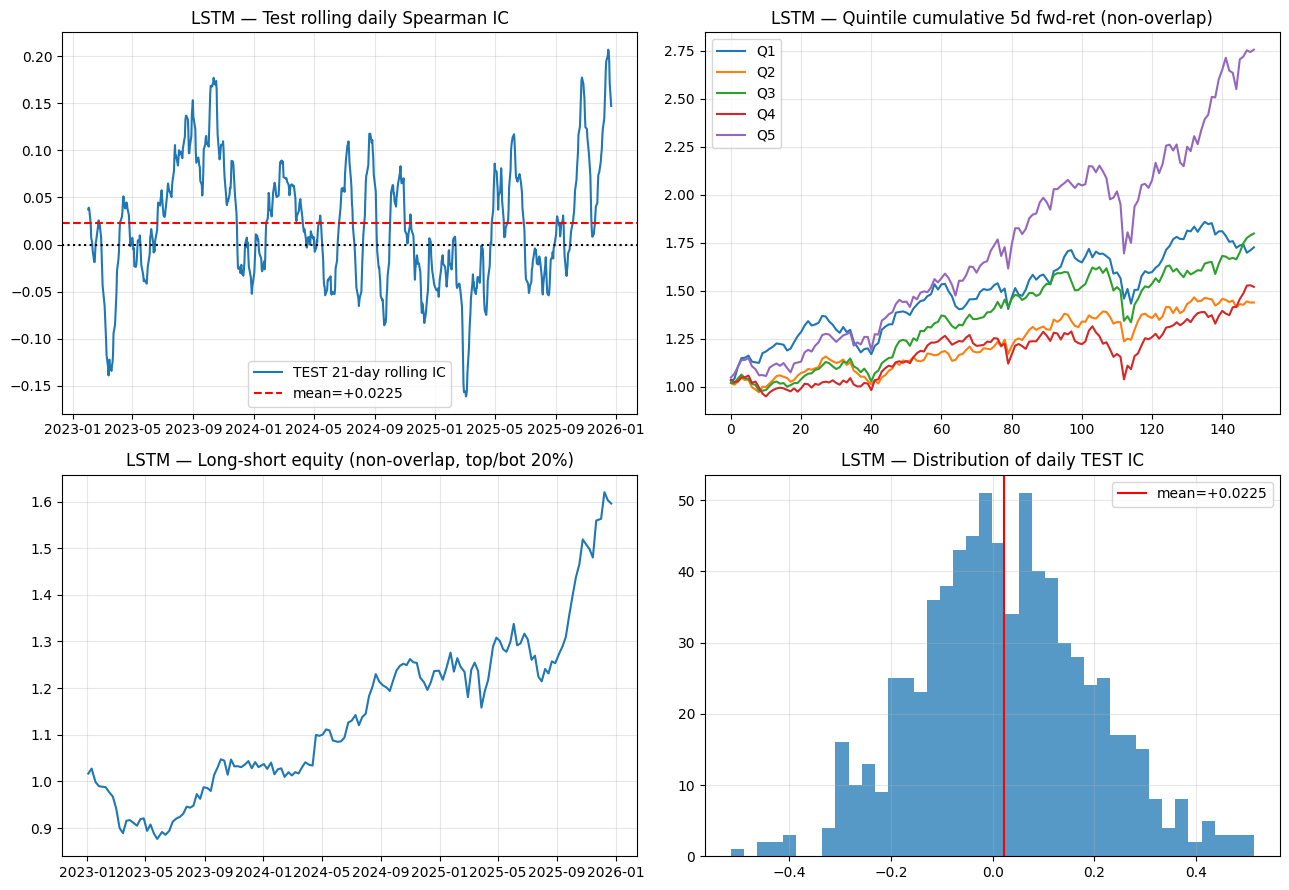

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# rolling IC
ic_sorted = ic_tst.sort_values("date")
axes[0,0].plot(ic_sorted["date"], ic_sorted["ic"].rolling(21).mean(),
               label="TEST 21-day rolling IC")
axes[0,0].axhline(0, ls=":", c="k")
axes[0,0].axhline(ic_tst["ic"].mean(), ls="--", c="r",
                  label=f"mean={ic_tst['ic'].mean():+.4f}")
axes[0,0].set_title("LSTM — Test rolling daily Spearman IC")
axes[0,0].legend(); axes[0,0].grid(alpha=.3)

# quintile cumulative curves (use non-overlap series for honest compounding)
q_no = quintile_returns(non_overlapping_subsample(test_df, step=FORWARD_DAYS))
q_no_sorted = q_no.sort_values("date").reset_index(drop=True)
for i in range(1, 6):
    (1 + q_no_sorted[f"q{i}"]).cumprod().plot(ax=axes[0,1], label=f"Q{i}")
axes[0,1].set_title("LSTM — Quintile cumulative 5d fwd-ret (non-overlap)")
axes[0,1].legend(); axes[0,1].grid(alpha=.3)

# L/S equity (non-overlap)
ls_no = lstm_eval["ls_no"].sort_values("date")
axes[1,0].plot(ls_no["date"], (1 + ls_no["ls_ret"]).cumprod())
axes[1,0].set_title(f"LSTM — Long-short equity (non-overlap, top/bot {int(TOP_Q*100)}%)")
axes[1,0].grid(alpha=.3)

# IC histogram
axes[1,1].hist(ic_tst["ic"].dropna(), bins=40, alpha=.75)
axes[1,1].axvline(ic_tst["ic"].mean(), c="r",
                  label=f"mean={ic_tst['ic'].mean():+.4f}")
axes[1,1].set_title("LSTM — Distribution of daily TEST IC")
axes[1,1].legend(); axes[1,1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lstm_diagnostics.png"), dpi=120)
plt.show()


## 15. Walk-forward retraining

Skip this cell if you're time-constrained — it adds ~20–30 min on a T4 GPU because it trains 5 seeds × 3 years = 15 LSTMs. The payoff is an honest yearly-refit number to compare against the naive single-train above.

In [15]:
def walk_forward_lstm(ds_feat, test_years, seq_len, seeds=SEEDS, val_days=180, verbose=True):
    all_preds = []
    for ys, ye in test_years:
        ys_ts, ye_ts = pd.to_datetime(ys), pd.to_datetime(ye)

        # window of data available for this fold (features + target)
        fold_all = ds_feat[ds_feat["date"] <= ye_ts].copy()

        # build sequences ONCE for the fold
        X_f, y_f, d_f, t_f = build_sequences(fold_all, FEATURE_COLS, seq_len)

        is_test  = (d_f >= np.datetime64(ys_ts)) & (d_f <= np.datetime64(ye_ts))
        val_cut  = ys_ts - pd.Timedelta(days=val_days)
        is_val   = (d_f >= np.datetime64(val_cut)) & (d_f < np.datetime64(ys_ts))
        is_train = d_f < np.datetime64(val_cut)

        Xtr, ytr, dtr = X_f[is_train], y_f[is_train], d_f[is_train]
        Xva, yva, dva = X_f[is_val],   y_f[is_val],   d_f[is_val]
        Xte, yte, dte_loc, tte_loc = X_f[is_test], y_f[is_test], d_f[is_test], t_f[is_test]

        if verbose:
            print(f"\n### Walk-forward year {ys[:4]} | train n={len(Xtr):,}  val n={len(Xva):,}  test n={len(Xte):,}")

        preds_te = np.zeros(len(Xte), dtype=np.float64)
        for seed in seeds:
            model, val_ic = train_one_lstm(seed, Xtr, ytr, Xva, yva, dva)
            preds_te += predict_lstm(model, Xte) / len(seeds)
            if verbose:
                print(f"  year={ys[:4]} seed={seed}  val_IC={val_ic:+.4f}")

        fold_df = pd.DataFrame({
            "date": dte_loc, "ticker": tte_loc, "pred": preds_te, "target": yte,
        }).merge(fold_all[["date","ticker","fwd_ret"]], on=["date","ticker"], how="left")
        all_preds.append(fold_df)

    return pd.concat(all_preds, ignore_index=True)

# Uncomment to run walk-forward (expensive!)
# test_years = [("2023-01-01","2023-12-31"),
#               ("2024-01-01","2024-12-31"),
#               ("2025-01-01","2025-12-31")]
# wf_test = walk_forward_lstm(ds, test_years, SEQ_LEN)
# wf_eval = honest_eval_block(wf_test, label="LSTM WALK-FORWARD (yearly refit)")


## 16. Save artefacts

In [16]:
valid_df.to_csv(os.path.join(OUTPUT_DIR, "lstm_preds_valid.csv"), index=False)
test_df .to_csv(os.path.join(OUTPUT_DIR, "lstm_preds_test.csv"),  index=False)
ic_val.to_csv(os.path.join(OUTPUT_DIR, "lstm_ic_valid.csv"), index=False)
ic_tst.to_csv(os.path.join(OUTPUT_DIR, "lstm_ic_test.csv"),  index=False)
ls_val.to_csv(os.path.join(OUTPUT_DIR, "lstm_ls_valid.csv"), index=False)
ls_tst.to_csv(os.path.join(OUTPUT_DIR, "lstm_ls_test.csv"),  index=False)

summary = {
    "config": {
        "universe_size": int(ds["ticker"].nunique()),
        "seq_len": SEQ_LEN,
        "n_features": N_FEATURES,
        "hidden": HIDDEN,
        "num_layers": NUM_LAYERS,
        "dropout": DROPOUT,
        "ensemble_size": len(SEEDS),
        "forward_days": FORWARD_DAYS,
    },
    "per_seed_val_ic":  seed_ics,
    "ensemble_val_ic":  float(ic_val["ic"].mean()),
    "ensemble_val_ir":  float(_ir(ic_val)),
    "ensemble_test_ic": float(ic_tst["ic"].mean()),
    "ensemble_test_ir": float(_ir(ic_tst)),
    "q5_minus_q1_test_5d": float(q_tst["ls_q5_q1"].mean()),
    "test_sharpe_naive":    lstm_eval["naive"]["Sharpe"],
    "test_sharpe_hac":      lstm_eval["hac_sr"],
    "test_sharpe_nonolap":  lstm_eval["no_stats"]["Sharpe"],
    "test_cagr_nonolap":    lstm_eval["no_stats"]["CAGR"],
    "test_maxdd_nonolap":   lstm_eval["no_stats"]["MaxDD"],
}
with open(os.path.join(OUTPUT_DIR,"lstm_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)

print("Saved:", sorted(os.listdir(OUTPUT_DIR)))
summary


Saved: ['lstm_diagnostics.png', 'lstm_ic_test.csv', 'lstm_ic_valid.csv', 'lstm_ls_test.csv', 'lstm_ls_valid.csv', 'lstm_preds_test.csv', 'lstm_preds_valid.csv', 'lstm_seed11.pt', 'lstm_seed22.pt', 'lstm_seed33.pt', 'lstm_seed44.pt', 'lstm_seed55.pt', 'lstm_summary.json']


{'config': {'universe_size': 65,
  'seq_len': 30,
  'n_features': 8,
  'hidden': 64,
  'num_layers': 2,
  'dropout': 0.3,
  'ensemble_size': 5,
  'forward_days': 5},
 'per_seed_val_ic': [0.02426730402769928,
  0.026256751778212295,
  0.029155283639773454,
  0.019729803882978163,
  0.022939475203459972],
 'ensemble_val_ic': 0.03316169417064049,
 'ensemble_val_ir': 0.1720811873485247,
 'ensemble_test_ic': 0.022549164714524884,
 'ensemble_test_ir': 0.13174707870455574,
 'q5_minus_q1_test_5d': 0.002321177872870771,
 'test_sharpe_naive': 0.8175281444011836,
 'test_sharpe_hac': 1.105350984950042,
 'test_sharpe_nonolap': 1.1848494126100768,
 'test_cagr_nonolap': 0.16999903773336889,
 'test_maxdd_nonolap': -0.14677384983311714}